# Context Engineering for driver_agent — plan & working notebook

Paper working title: **Obligation-Anchored Context Distillation for LLM Driver Migration**
(alt: *What Context Does Kernel Driver Migration Actually Need?*).

Branch: `context-engineering` (off `main`). Started 2026-08-04 from the
`context_meeting.pptx` deck (Jul 2026). This notebook is the living plan for the
direction: problem statement, status-quo code map, roadmap, and charts over locally
available artifacts. Analysis cells are defensive: they skip data that is not present
on this machine.

**Environment** (not the nix devshell; jupyter/matplotlib are intentionally kept out of it):
```bash
python3 -m venv .venv-analysis
.venv-analysis/bin/pip install jupyter nbclient matplotlib pandas
.venv-analysis/bin/jupyter nbconvert --to notebook --execute --inplace notebooks/context_engineering_plan.ipynb
```

## 1. Problem

Patch quality depends on what we put in the prompt; the budget is limited and large
cases overflow it. Current trimming is blind — line utility is never scored.

Status-quo code map (verified 2026-08-04, branch point `main`@fbc30c1):

| What | Where |
|---|---|
| Global char budget `DEFAULT_PATCH_INPUT_BUDGET_CHARS = 180000` | `driver_agent_pregen/patch_generation.py:17` |
| Payload assembly order (checklist, obligations, edit_scope, pre_reasoning, context_packet, old_module_sources) | `patch_generation.py:2044-2068` |
| Focused sources: edit_required/candidate/context blocks + read-only callers/includes | `patch_generation.py::_build_focused_old_sources` (:285) |
| **Silent drops**: 3-stage shrink; final stage drops *all* read-only sources, model is never told | `patch_generation.py::_shrink_patch_input_payload` (:1070-1118) |
| Head/tail clip 0.68/0.22, per-kind caps 2600/4600/5200 | `patch_generation.py::_compact_source_content` (:1046), `_source_content_cap` (:1060) |
| Scattered independent trimming #2 | `utils.py:194` `truncate_text` (head clip, used ad hoc everywhere) |
| Scattered independent trimming #3 | `spec_agent.py` (3500-char slices, per-tier caps 800/700/600) |
| Scattered independent trimming #4 | `reasoner_agent.py` (near-duplicate of spec_agent logic) |

Consequence: compression policy lives in four modules, cannot be ablated, and the
model silently loses read-only context exactly on the large cases where it matters.

## 2. Method core (from the deck + literature)

- **Selection unit**: *dependency closure* — a function plus the types/macros it needs to
  stay expressible. Ingredients already exist: `symbol_scanner.py` per-function
  calls/types/fields/macros extraction (:273-307, aggregate `driver_used_symbols.json`),
  `definition_locator.py` per-kind definition resolution.
- **Value signal**: overlap with obligation symbols; coefficients calibrated on mined
  migrations, stored as an auditable artifact.
- **Keep the edit locus verbatim, drop the rest** (Sam-Bodden 2026: skeleton/LOD tiers
  are no better than dropping, p=0.75; value lives in *find*, not in clever *act*
  representations). Submodular coverage under budget.
- **Judge**: build oracle + expressibility gate. No trained compressor (JetBrains null:
  latent compressors break on iterative agent loops).
- Three assets no prior work combines: machine-derived task spec (obligations), free
  gold context (kernel git history), real oracle (kernel build).

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt

REPO = Path.cwd()
if not (REPO / 'datasets').exists() and (REPO.parent / 'datasets').exists():
    REPO = REPO.parent  # allow running from notebooks/
BUDGET_CHARS = 180_000  # patch_generation.py:17
CHARS_PER_LOC = 35      # rough kernel-C average, for LOC -> chars scale only

manifests = {}
for mf in sorted((REPO / 'datasets').glob('*/manifest.csv')):
    try:
        df = pd.read_csv(mf)
        df['dataset'] = mf.parent.name
        manifests[mf.parent.name] = df
    except Exception as e:
        print(f'skip {mf}: {e}')
print(f'{len(manifests)} dataset manifests loaded:')
for name, df in manifests.items():
    print(f'  {name}: {len(df)} cases, cols={list(df.columns)[:6]}...')

12 dataset manifests loaded:
  intree_hardbreak_20_v0: 20 cases, cols=['case_id', 'role', 'old_ref', 'new_ref', 'module_path', 'source_file_count']...
  intree_kbuild_target_hardbreak_20_v0: 20 cases, cols=['case_id', 'role', 'old_ref', 'new_ref', 'module_path', 'module_target']...
  intree_mini_v0: 10 cases, cols=['case_id', 'module_path', 'category', 'modified_loc', 'code_loc', 'source_file_count']...
  intree_showcase_5_v0: 5 cases, cols=['case_id', 'old_ref', 'new_ref', 'module_path', 'module_target', 'target_name']...
  intree_single_module_hardbreak_v0: 5 cases, cols=['case_id', 'kind', 'old_ref', 'new_ref', 'module_path', 'kbuild_unit']...
  intree_strict_testable_hardbreak_v1: 7 cases, cols=['case_id', 'role', 'old_ref', 'new_ref', 'module_path', 'source_file_count']...
  intree_testable_hardbreak_v0: 20 cases, cols=['case_id', 'case_kind', 'old_ref', 'new_ref', 'module_path', 'test_kind']...
  intree_unique_hardbreak_20_v0: 20 cases, cols=['case_id', 'role', 'old_ref', 'new_re

### 2.1 Case scale vs. the 180k budget

How big are the modules our datasets target, relative to the prompt budget? LOC from
dataset manifests, converted to approximate chars (~35 chars/LOC for kernel C). This
is module *source* size only — the payload also carries obligations, kernel evidence
and read-only context on top, so bars near or above the line are exactly the cases
where today's silent dropping fires.

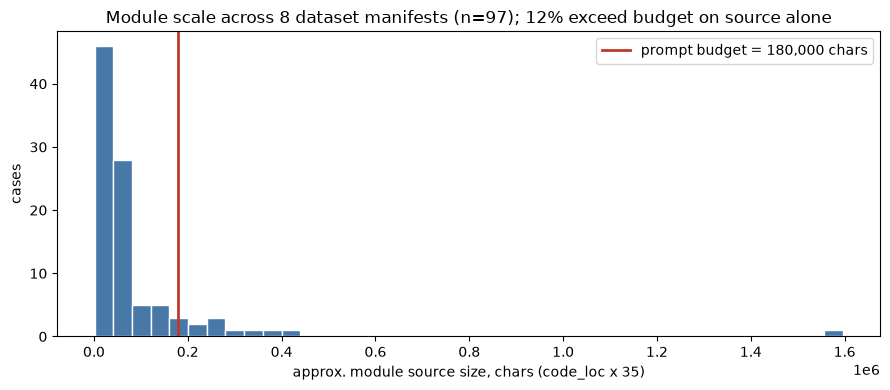

In [2]:
frames = [df for df in manifests.values() if 'code_loc' in df.columns]
if frames:
    allcases = pd.concat(frames, ignore_index=True)
    allcases = allcases.dropna(subset=['code_loc'])
    allcases['approx_chars'] = allcases['code_loc'] * CHARS_PER_LOC
    fig, ax = plt.subplots(figsize=(9, 4))
    ax.hist(allcases['approx_chars'], bins=40, color='#4878a8', edgecolor='white')
    ax.axvline(BUDGET_CHARS, color='#c0392b', lw=2,
               label=f'prompt budget = {BUDGET_CHARS:,} chars')
    ax.set_xlabel('approx. module source size, chars (code_loc x 35)')
    ax.set_ylabel('cases')
    over = (allcases['approx_chars'] > BUDGET_CHARS).mean()
    ax.set_title(f'Module scale across {allcases["dataset"].nunique()} dataset manifests '
                 f'(n={len(allcases)}); {over:.0%} exceed budget on source alone')
    ax.legend()
    plt.tight_layout(); plt.show()
else:
    print('no manifest with code_loc found locally — TODO: regenerate on retro')

### 2.2 Edit size vs. module size

The reference edits are tiny relative to the modules — the ratio *edit locus : total
context* is the headroom a scored selection can exploit.

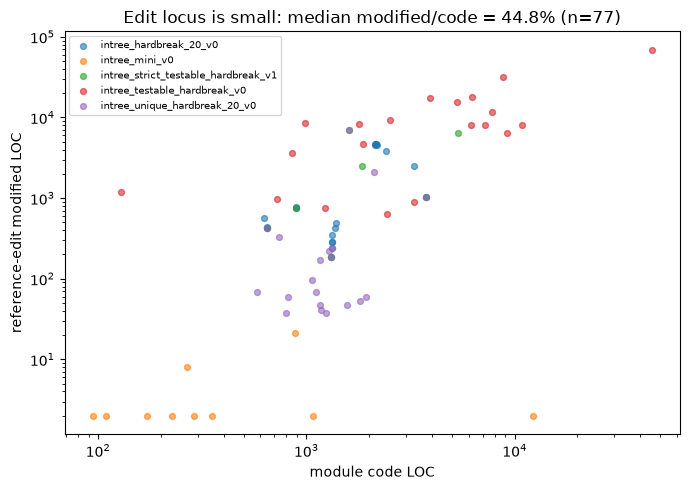

In [3]:
frames = [df for df in manifests.values()
          if {'code_loc', 'modified_loc'} <= set(df.columns)]
if frames:
    df = pd.concat(frames, ignore_index=True).dropna(subset=['code_loc', 'modified_loc'])
    df = df[(df['code_loc'] > 0) & (df['modified_loc'] > 0)]
    fig, ax = plt.subplots(figsize=(7, 5))
    for name, g in df.groupby('dataset'):
        ax.scatter(g['code_loc'], g['modified_loc'], s=18, alpha=0.6, label=name)
    ax.set_xscale('log'); ax.set_yscale('log')
    ax.set_xlabel('module code LOC'); ax.set_ylabel('reference-edit modified LOC')
    med = (df['modified_loc'] / df['code_loc']).median()
    ax.set_title(f'Edit locus is small: median modified/code = {med:.1%} (n={len(df)})')
    ax.legend(fontsize=7, loc='upper left')
    plt.tight_layout(); plt.show()
else:
    print('no manifest with code_loc+modified_loc found locally')

## 3. Roadmap

1. **Eval setup first** (this session): `tools/ppl_context_scorer.py`
   (expressibility gate + pluggable teacher-forced-NLL scorer + disk cache) and
   `tools/run_ppl_signal_experiment.py` (conditions, win-rates, CSV/MD, `--reparse`).
   Smoke on the existing `datasets/intree_mini_v0` case packs — no miner needed.
2. **Step 0 — benchmark miner** `tools/mine_migration_bench.py` (design in §5).
3. **Step 1 — PPL signal check** on mined cases, against the pre-registered criterion
   in `docs/ppl_signal_preregistration.md`. *Kill signal in days*: no correlation →
   keep only the deterministic half (gate + obligation-symbol overlap + submodular
   coverage).
4. **`context_pruner.py`** behind a default-off flag, ablations (incl. the ETH null:
   ablate `pre_spec`/`pre_reasoner` sections), full pipeline runs.

Heavy runs go to build host `retro` (16-core NixOS, full linux.git with v6.19/v7.0-rc1).

## 4. Eval design (what the harness measures)

Per case, the prompt = instruction + *candidate context block* + old function slices;
target = `reference.diff`. All conditions are **size-matched** to a fixed char budget
(length is the dominant confound). Conditions:

| condition | contents | expectation |
|---|---|---|
| `gold` | gold kernel-side definitions/diffs for this case | lowest PPL, gate ~100% |
| `gold+distractors` | gold + same-commit unused symbol defs | ≈ gold or slightly worse |
| `distractors-only` | plausible but unused defs (negative control) | ≈ none |
| `random` | gold context of a *different* case, size-matched | ≈ none or worse |
| `none` | empty context | baseline |

Metrics: per-case win rates PPL(gold) < PPL(random/none/distractors); Spearman between
condition-quality rank and PPL rank; expressibility-gate pass rate per condition (the
gate is validated independently of PPL: gold ≈ 100%, none/random low).

Scorer: teacher-forced NLL of the target given the prompt, local
`Qwen/Qwen2.5-Coder-0.5B` on CPU (only the *ranking* matters, not absolute PPL);
OpenRouter raw `/completions` echo+logprobs as a flagged fallback. sha256 disk cache
keyed by (model, prompt, target) — reruns are free.

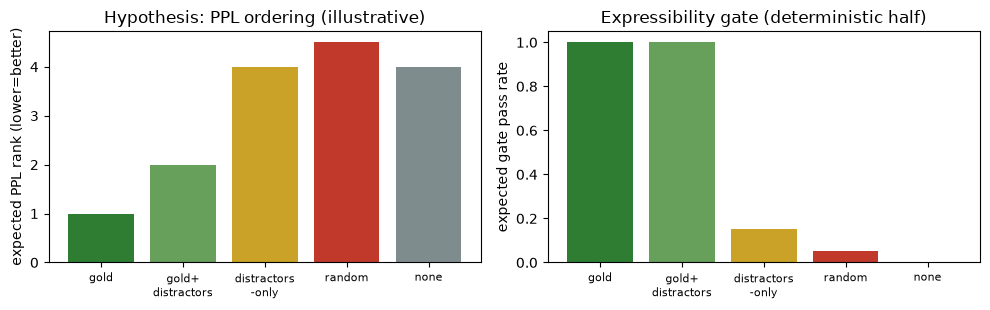

Pre-registered (docs/ppl_signal_preregistration.md):
  SUCCESS: gold<random >=70% AND gold<none >=60% of cases, sign test p<0.01
  KILL:    gold-vs-random win rate <60% -> drop PPL, keep deterministic half
  60-70%:  one retry with a 1.5B model, then decide; no further tuning


In [4]:
# Design illustration (NOT data): the score ordering the PPL check must reproduce
# for SUCCESS, mirrored by expected expressibility-gate pass rates.
conds = ['gold', 'gold+\ndistractors', 'distractors\n-only', 'random', 'none']
expected_ppl_rank = [1, 2, 4, 4.5, 4]          # lower = better (illustrative)
expected_gate = [1.0, 1.0, 0.15, 0.05, 0.0]    # identifier coverage (illustrative)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
axes[0].bar(conds, expected_ppl_rank, color=['#2e7d32', '#66a05b', '#c9a227', '#c0392b', '#7f8c8d'])
axes[0].set_ylabel('expected PPL rank (lower=better)')
axes[0].set_title('Hypothesis: PPL ordering (illustrative)')
axes[1].bar(conds, expected_gate, color=['#2e7d32', '#66a05b', '#c9a227', '#c0392b', '#7f8c8d'])
axes[1].set_ylabel('expected gate pass rate')
axes[1].set_title('Expressibility gate (deterministic half)')
for ax in axes:
    ax.tick_params(axis='x', labelsize=8)
plt.tight_layout(); plt.show()
print('Pre-registered (docs/ppl_signal_preregistration.md):')
print('  SUCCESS: gold<random >=70% AND gold<none >=60% of cases, sign test p<0.01')
print('  KILL:    gold-vs-random win rate <60% -> drop PPL, keep deterministic half')
print('  60-70%:  one retry with a 1.5B model, then decide; no further tuning')

## 5. Miner design digest (Step 0, deferred)

**Primary mode — atomic treewide-migration commits.** A commit that changes a kernel
API *and* adapts callers in the same change is self-labeling: kernel-side hunks =
gold context, driver-side hunks = reference edit.

1. One-pass scan: `git log --no-merges --name-only old..new`; keep commits touching
   both a kernel prefix (`include/`, opt. `kernel/ mm/ block/ lib/`) and a caller
   prefix (`drivers/`, `sound/`).
2. Per commit: `git show -M`; each touched driver `.c` → one case
   (`reference.diff` = commit diff restricted to the file; old source at `commit^`).
3. **Gold labels**: symbols extracted from kernel-side hunks ∩ tokens of the caller
   edit → `gold_symbols` (invariant: present in both diffs, hard-fail otherwise);
   same-commit unused symbols → `distractor_symbols` (free negatives).
4. Quality gates: drop renames/comment-only edits, `min/max-caller-changed-lines`
   (2..200), `--max-cases-per-commit` cap (treewide sed commits), record
   `treewide_scale` for stratification.

Reuse: `_parse_diff_changed_lines`/`_map_lines_to_functions` from
`tools/build_candidate_small_dataset.py`; `RepositoryAccessor` (`repo_utils.py`) for
excerpts/pickaxe; case-pack layout from `tools/build_intree_mini_dataset.py`;
evidence-item shape from `kernel_definition_diffs.json`.

Expected volume v6.19..v7.0-rc1: ~500-2000 cases, minutes-to-30min on retro.
Secondary `--mode split-commits` (pickaxe `log_s`) only if volume is thin.
Everything is `evaluation_only: true` — reference diffs never enter the agent pipeline.

## 6. Risks

- **Atomic-commit bias**: over-samples mechanical migrations; mitigated by
  `treewide_scale` stratification and a later split-commits mode.
- **Gold-label noise**: token intersection misses typedef/macro indirection; gauge =
  0-gold-symbol rate (>20% → fix extraction before Step 1).
- **Length confound**: size-matching mandatory; also report NLL/token.
- **0.5B transferability**: Step 1 tests whether the signal *exists*, not its final
  strength on frontier models — stated in the pre-registration.
- **Input boundary**: everything here is evaluation harness; anything later promoted
  into `driver_agent_pregen/` (pruner) must be audited to never see reference diffs.